# 04 · Simulating held-out Champions League seasons

Match probabilities are a means to an end: the question people actually ask is *"who wins the Champions League?"*. We answer it by **Monte-Carlo simulation of the whole tournament** using the match model, then score those forecasts against what actually happened in seasons the models never trained on.

## Design

For each held-out season with the classic 32-team format (2021/22, 2022/23, 2023/24 — the 2024/25 league phase needs a different simulator):

1. **Freeze information at kick-off.** Ratings, form and experience are taken from the rating state as of the day before the season starts (it only contains earlier seasons).
2. **Use the real group draw** (groups and fixtures are known at that point), simulate all 96 group matches from the model's (home, draw, away) probabilities, and rank by points → simulated goal difference → coin flip.
3. **Draw the round of 16 under UEFA's constraints** (group winner vs runner-up, different group, different association), then draw quarter-finals and semi-finals at random, as UEFA does. Two-legged ties use the first-leg / second-leg models; the final is a neutral single match.
4. Repeat **20,000 times** and read off, for every club, the probability of reaching each round and of winning the trophy.

**Simplifications** (also in the model card): ratings are frozen during the tournament; the model predicts 90-minute outcomes, so goal margins are sampled from the empirical training distribution given the outcome; ties level after two legs and drawn finals are decided by a fair coin (extra time and penalties); no head-to-head tie-breaks.

**Models compared** (all calibrated on the validation seasons, identical simulator): Uniform (every match 1/3-1/3-1/3, so every club has a 1/32 title chance), Elo logistic regression, all-features logistic regression, gradient boosting, and the 5-seed neural network, loaded back from the saved artifact to prove the persistence path works.

In [1]:
import json
import subprocess
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from ucl import experiments as X
from ucl import plotting as P
from ucl.config import MODELS_DIR, SEED, SIMULATION_SEASONS
from ucl.models import Ensemble, MLPModel
from ucl.simulation import (
    STAGE_NAMES,
    MarginSampler,
    actual_stage_reached,
    forecast_scores,
    probability_tensor,
    season_setup,
    simulate_season,
    state_before_season,
)

P.apply_style()
pd.set_option("display.width", 140)
T0 = time.perf_counter()
N_SIMS = 20_000
ds = X.load_dataset()
tr, va, te = ds.train, ds.val, ds.test
hp = X.load_json("baseline_hparams.json")
base = X.fit_baselines(tr, va, hp)
art = MODELS_DIR / "ucl_mlp"
meta = json.loads((art / "artifact.json").read_text())
mlp = Ensemble(
    [MLPModel.load(art / f"member_{i}") for i in range(meta["n_members"])],
    name="MLP + team embeddings (x5 ensemble)",
)
models = {"Uniform": base["Uniform"]}
for k in ["Elo + logistic regression", "All features + logistic regression", "Gradient boosting"]:
    models[k] = X.calibrate(base[k], va)
models[mlp.name] = X.calibrate(mlp, va)
ms = MarginSampler(tr.goal_diff.to_numpy())  # margin distribution from training data only
display(
    Markdown(
        f"Loaded {len(models)} models; neural network restored from `{art.name}` (temperature {models[mlp.name].temperature:.2f}). Seasons simulated: {[f'{s}/{(s + 1) % 100:02d}' for s in SIMULATION_SEASONS]}."
    )
)

Loaded 5 models; neural network restored from `ucl_mlp` (temperature 1.05). Seasons simulated: ['2021/22', '2022/23', '2023/24'].

In [2]:
t = time.perf_counter()
sims, truth, scores = {}, {}, []
for season in SIMULATION_SEASONS:
    setup = season_setup(ds.matches, season)
    state = state_before_season(ds.matches, season, ds.elo_params)
    truth[season] = actual_stage_reached(ds.matches, season)
    for name, model in models.items():
        probs = probability_tensor(model, state, setup)
        sim = simulate_season(setup, probs, ms, n_sims=N_SIMS, seed=SEED)
        assert np.isclose(sim["Winner"].sum(), 1.0) and np.allclose(
            sim.sum().to_numpy(), [32, 16, 8, 4, 2, 1]
        )
        sims[(season, name)] = sim
        scores.append(
            {
                "season": f"{season}/{(season + 1) % 100:02d}",
                "model": name,
                **forecast_scores(sim, truth[season], N_SIMS),
            }
        )
scores = pd.DataFrame(scores)
sim_s = time.perf_counter() - t
display(
    Markdown(
        f"{len(sims)} simulations x {N_SIMS:,} tournaments in {sim_s:.0f}s. Every simulated season's title probabilities sum to 1 and stage survivors sum to 32/16/8/4/2/1 (asserted)."
    )
)

15 simulations x 20,000 tournaments in 9s. Every simulated season's title probabilities sum to 1 and stage survivors sum to 32/16/8/4/2/1 (asserted).

## Title probabilities from the neural network

Bars show the model's pre-season probability of winning the trophy for the eight most likely clubs; the **actual champion is red**.

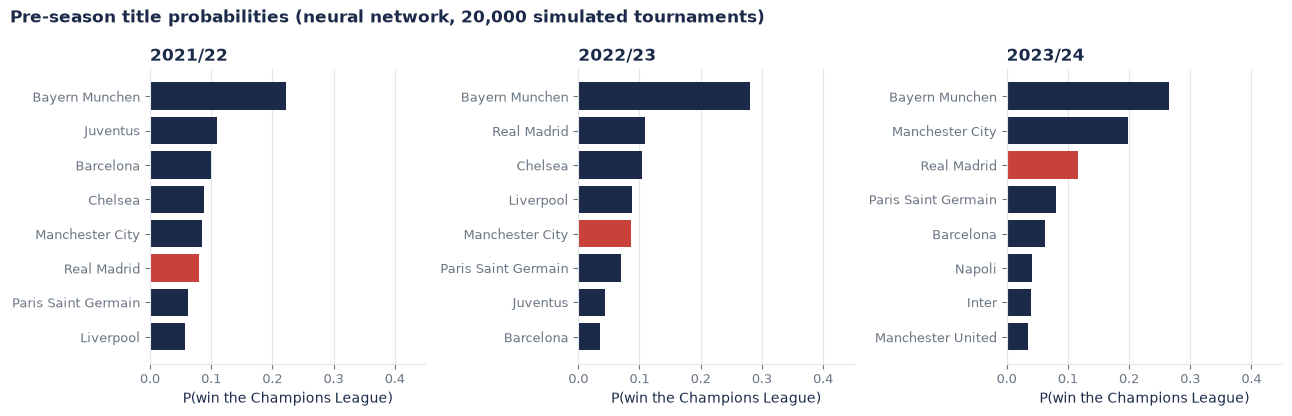

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, season in zip(axes, SIMULATION_SEASONS, strict=False):
    sim = sims[(season, mlp.name)]
    champ = truth[season][truth[season] == 5].index[0]
    top = sim.Winner.sort_values(ascending=False).head(8)
    if champ not in top.index:
        top = pd.concat([top.head(7), sim.Winner[[champ]]])
    top = top[::-1]
    ax.barh(
        [P.pretty_team(t) for t in top.index],
        top.values,
        color=[P.COLORS["red"] if t == champ else P.COLORS["navy"] for t in top.index],
    )
    ax.set_title(f"{season}/{(season + 1) % 100:02d}")
    ax.set_xlabel("P(win the Champions League)")
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, 0.45)
fig.suptitle(
    "Pre-season title probabilities (neural network, 20,000 simulated tournaments)",
    x=0.01,
    ha="left",
    fontweight="bold",
    color=P.INK,
)
fig.tight_layout()
P.save(fig, "champion_probabilities")
plt.show()

## Scoring the forecasts

* **P(actual champion)** and its negative log (**log score**; lower is better; uniform = ln 32 = 3.47).
* **Champion Brier**: squared error of the full 32-way title distribution (uniform ≈ 0.97 whichever club wins).
* **Stage Brier**: mean Brier score over five binary events per club — reaching the round of 16, quarter-final, semi-final, final, winning — which uses all 32 clubs' fates rather than the single champion, and is therefore far less noisy than the champion score alone.

In [4]:
champ_p = scores.pivot(index="model", columns="season", values="champion_prob").loc[list(models)]
champ_p["mean log score"] = scores.groupby("model").champion_logscore.mean()
summary = (
    scores.groupby("model")[["champion_logscore", "champion_brier", "stage_brier"]].mean().loc[list(models)]
)
display(Markdown("**Probability each model gave to the club that actually won**"))
display(champ_p.round(3))
display(Markdown("**Mean over the three seasons** (lower is better)"))
display(summary.round(4))

**Probability each model gave to the club that actually won**

season,2021/22,2022/23,2023/24,mean log score
model,,,,
Uniform,0.031,0.033,0.033,3.441
Elo + logistic regression,0.094,0.097,0.148,2.201
All features + logistic regression,0.085,0.086,0.121,2.344
Gradient boosting,0.094,0.098,0.138,2.222
MLP + team embeddings (x5 ensemble),0.080,0.086,0.116,2.375


**Mean over the three seasons** (lower is better)

,champion_logscore,champion_brier,stage_brier
model,,,
Uniform,3.4409,0.9672,0.1273
Elo + logistic regression,2.2014,0.9259,0.1008
All features + logistic regression,2.3441,0.9341,0.1008
Gradient boosting,2.2219,0.8901,0.1014
MLP + team embeddings (x5 ensemble),2.3746,0.9363,0.1007


In [5]:
u, m = summary.loc["Uniform"], summary.loc[mlp.name]
e = summary.loc["Elo + logistic regression"]
best_stage = summary.stage_brier.idxmin()
display(
    Markdown(
        f"* Every informed model beats the uniform forecast on the stage-level Brier score ({u.stage_brier:.4f} → {summary.stage_brier.drop('Uniform').min():.4f} … {summary.stage_brier.drop('Uniform').max():.4f}); "
        f"the four informed models are within {summary.stage_brier.drop('Uniform').max() - summary.stage_brier.drop('Uniform').min():.4f} of each other (network {m.stage_brier:.4f}, Elo logistic regression {e.stage_brier:.4f}), i.e. **no separation** — consistent with the match-level result that the network ties the baselines rather than beating them.\n"
        f"* For the champion alone the network's mean log score is {m.champion_logscore:.2f} versus {u.champion_logscore:.2f} for uniform. "
        f"With **three seasons, three trophies** this number is anecdotal: a single upset (e.g. a 6% club winning) swings it by more than the differences between models. "
        f"Do not read the ranking of the informed models off the champion score."
    )
)

* Every informed model beats the uniform forecast on the stage-level Brier score (0.1273 → 0.1007 … 0.1014); the four informed models are within 0.0007 of each other (network 0.1007, Elo logistic regression 0.1008), i.e. **no separation** — consistent with the match-level result that the network ties the baselines rather than beating them.
* For the champion alone the network's mean log score is 2.37 versus 3.44 for uniform. With **three seasons, three trophies** this number is anecdotal: a single upset (e.g. a 6% club winning) swings it by more than the differences between models. Do not read the ranking of the informed models off the champion score.

## Is the simulated bracket calibrated?

Pool every (club, season, stage) event — 3 seasons x 32 clubs x 4 knock-out stages = 384 binary outcomes ("did this club reach the quarter-final?") — bin by forecast probability, and compare with what happened. This is a much richer calibration test of the *simulation* than the three champions.

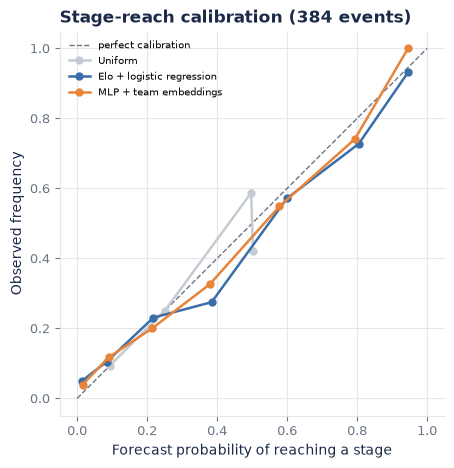

Network: pooled Brier 0.1186 over 384 events; mean forecast 0.234 vs observed rate 0.234 (they must coincide: 30 of the 128 club-stage slots are filled each season). Low-probability clubs reach later rounds somewhat more often than forecast (first bin: 0.016 forecast vs 0.039 observed), the usual signature of under-dispersed favourites; with 384 events this is suggestive, not conclusive.

,forecast,observed,n
0,0.016,0.039,127
1,0.090,0.117,77
2,0.214,0.200,65
3,0.379,0.326,46
4,0.578,0.548,31
5,0.793,0.741,27
6,0.945,1.000,11


In [6]:
def pooled(model):
    pr, ob = [], []
    for season in SIMULATION_SEASONS:
        sim, tru = sims[(season, model)], truth[season].reindex(sims[(season, model)].index)
        for k in range(1, 5):
            pr += sim[STAGE_NAMES[k]].tolist()
            ob += (tru >= k).astype(float).tolist()
    return np.array(pr), np.array(ob)


edges = np.array([0, 0.05, 0.15, 0.3, 0.5, 0.7, 0.9, 1.0])
fig, ax = plt.subplots(figsize=(5.4, 5.0))
ax.plot([0, 1], [0, 1], color=P.MUTED, ls="--", lw=1, label="perfect calibration")
tabs = {}
for name in ["Uniform", "Elo + logistic regression", mlp.name]:
    pr, ob = pooled(name)
    idx = np.digitize(pr, edges[1:-1])
    rows = [
        (pr[idx == b].mean(), ob[idx == b].mean(), int((idx == b).sum()))
        for b in range(len(edges) - 1)
        if (idx == b).sum() >= 8
    ]
    t = pd.DataFrame(rows, columns=["forecast", "observed", "n"])
    tabs[name] = t
    ax.plot(
        t.forecast,
        t.observed,
        "o-",
        color=P.model_color(name),
        lw=1.8,
        ms=5,
        label=name.replace(" (x5 ensemble)", ""),
    )
ax.set_xlabel("Forecast probability of reaching a stage")
ax.set_ylabel("Observed frequency")
ax.set_title("Stage-reach calibration (384 events)")
ax.legend(fontsize=7.5, loc="upper left")
ax.set_aspect("equal")
P.save(fig, "stage_calibration")
plt.show()
pr, ob = pooled(mlp.name)
display(
    Markdown(
        f"Network: pooled Brier {np.mean((pr - ob) ** 2):.4f} over {len(pr)} events; mean forecast {pr.mean():.3f} vs observed rate {ob.mean():.3f} (they must coincide: 30 of the 128 club-stage slots are filled each season). Low-probability clubs reach later rounds somewhat more often than forecast (first bin: {tabs[mlp.name].forecast[0]:.3f} forecast vs {tabs[mlp.name].observed[0]:.3f} observed), the usual signature of under-dispersed favourites; with 384 events this is suggestive, not conclusive."
    )
)
tabs[mlp.name].round(3)

## From the command line

The saved artifact is wrapped by a pydantic-validated CLI (`ucl-predict`), which shares the exact feature code used above. Ratings are as of the last match in the data (30 May 2026).

In [7]:
out = subprocess.run(
    [sys.executable, "-m", "ucl.predict", "Real Madrid", "Manchester City", "--stage", "knockout"],
    capture_output=True,
    text=True,
)
print(out.stdout or out.stderr)
bad = subprocess.run(
    [sys.executable, "-m", "ucl.predict", "Real Madrid", "Real Madrid"], capture_output=True, text=True
)
print("invalid input ->", (bad.stderr or bad.stdout).strip().splitlines()[0])
X.record_runtime("04_tournament_simulation", time.perf_counter() - T0)

Real Madrid vs Manchester City  (knockout)
  Real Madrid win   59.2%
  draw           23.1%
  Manchester City win   17.6%
  (Elo 1793 vs 1745, ratings as of 2026-05-30)



invalid input -> error: 1 validation error for MatchRequest


## Limitations — read before quoting any number

* **Small evaluation sample.** 753 test matches and 3 simulated trophies. Intervals on match log-loss are wide (±0.035) and the champion score is essentially anecdotal.
* **No betting odds.** Bookmaker prices are the real benchmark for football forecasting and are not in any open dataset used here; we cannot say how close these models are to the market (almost certainly further than they look).
* **Narrow information set.** Only Champions League results: no domestic league form, squad value, injuries, line-ups, travel or crowd. A club's strength is inferred from ~12 matches a year. Debutants start from a country-based prior.
* **Frozen ratings in the simulation**, simplified tie-breaks, coin-flip extra time / penalties, and no away-goals rule (correct for the simulated seasons, not for pre-2021 editions).
* **Regime changes.** The 2020/21 season was played largely without crowds, the 2019/20 knockout rounds were single games in Lisbon, and 2024/25 introduced the league phase. The first is invisible to the data, the others are only partly encoded in the features.
* **Data scope.** Qualifying rounds are excluded, club names are harmonised by a hand-built alias table (a missed alias would split a club's history), and 90-minute results are the target even though knockout ties are decided over 120 minutes.
* **Model selection on one validation window.** Hyper-parameters were chosen on four seasons; the validation and test seasons sometimes rank models differently (notebooks 02-03), which is a symptom of the small sample.
* **Disclosure.** While developing the pipeline an untuned prototype (default hyper-parameters) was run once and its test score seen; all reported hyper-parameters, architectures and calibration were then chosen on validation data only, and the architecture family was not changed afterwards.
* **Not for betting or any decision with money attached.** This is a methodology demonstration.